In [4]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from dataset import repeat_padding
import pickle

In [2]:
model = torch.load("/data/neil/antiRes/models1028/ocsoftmax/anti-spoofing_lfcc_model.pt")
model.eval()

/home/neil/anaconda3/envs/ocas/lib/python3.6/site-packages/torch/serialization.py:454: SourceChangeWarning: source code of class 'resnet.ResNet' has changed. you can retrieve the original source code by accessing the object's source attribute or set `torch.nn.Module.dump_patches = True` and use the patch tool to revert the changes.
  warnings.warn(msg, SourceChangeWarning)


ResNet(
  (conv1): Conv2d(1, 16, kernel_size=(9, 3), stride=(3, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (activation): ReLU()
  (layer1): Sequential(
    (0): PreActBlock(
      (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv1): Conv2d(16, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (shortcut): Sequential(
        (0): Conv2d(16, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      )
    )
    (1): PreActBlock(
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentu

In [98]:
def draw_attention(sample):
    print("Original num of frames:", sample.shape[1])
    if sample.shape[1] < 750:
        sample_ = repeat_padding(sample, 750)
        print("Padding")
    elif sample.shape[1] > 750:
        startp = np.random.randint(sample.shape[1]-750)
        sample_ = sample[:, startp:startp + 750]
        print("Truncate")
    else:
        sample_ = sample
    x = model.conv1(sample_.unsqueeze(0).unsqueeze(0))
    x = model.activation(model.bn1(x))
    x = model.layer1(x)
    x = model.layer2(x)
    x = model.layer3(x)
    x = model.layer4(x)
    x = model.conv5(x)
    x = model.activation(model.bn5(x)).squeeze(2)
    x = x.permute(0,2,1).contiguous()
    att_w = model.attention.att_weights
    weights = torch.bmm(x, att_w.permute(1,0).unsqueeze(0).repeat(x.shape[0], 1, 1))
    attentions = torch.nn.functional.softmax(torch.tanh(weights), dim=1)
    attention_line = attentions.cpu().detach().numpy()[0, : , 0]
#     fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6))
#     ax1.plot(attention_line)
#     ax1.set(xlim=[0, attentions.shape[1]])
#     ax2.pcolormesh(sample_.cpu().detach().numpy())
#     if sample.shape[1] < 750:
#         ax2.axvline(x=sample.shape[1])
    if sample.shape[1] < 750:
        pad_frame = int(np.floor(sample.shape[1] / 750 * attention_line.shape[0]))
        others = np.concatenate((attention_line[:pad_frame], attention_line[pad_frame+1:]))
        return (attention_line[pad_frame]+attention_line[min(93, pad_frame+1)]) / 2, others[3], others[23], others[56]
    else:
        return (attention_line[-1]+attention_line[0]) / 2, attention_line[3], attention_line[23], attention_line[56]


In [34]:
with open("/dataNVME/neil/ASVspoof2019LAFeatures/train/LA_T_7715241LFCC.pkl", 'rb') as feature_handle:
    sample1 = pickle.load(feature_handle)
    sample1 = torch.from_numpy(sample1).float().cuda()

In [45]:
draw_attention(sample1)

Original num of frames: 280
Padding


0.002437433

In [46]:
import pandas as pd

In [47]:
df = pd.read_csv("/dataNVME/neil/ASVspoof2019LAFeatures/trainSet_csv.csv")

In [67]:
files_to_chop = df[df["feat_len"] > 938]["filename"].tolist()
files_to_pad = df[df["feat_len"] <= 938]["filename"].tolist()

In [91]:
chop_res = []
for file in files_to_chop:
    with open("/dataNVME/neil/ASVspoof2019LAFeatures/train/"+file+"LFCC.pkl", 'rb') as feature_handle:
        sample1 = pickle.load(feature_handle)
        sample1 = torch.from_numpy(sample1).float().cuda()
        chop_res.append(draw_attention(sample1))

Original num of frames: 780
Truncate
Original num of frames: 1112
Truncate
Original num of frames: 878
Truncate
Original num of frames: 887
Truncate
Original num of frames: 778
Truncate
Original num of frames: 933
Truncate
Original num of frames: 843
Truncate
Original num of frames: 771
Truncate
Original num of frames: 772
Truncate
Original num of frames: 971
Truncate
Original num of frames: 786
Truncate
Original num of frames: 774
Truncate
Original num of frames: 791
Truncate
Original num of frames: 773
Truncate
Original num of frames: 845
Truncate
Original num of frames: 766
Truncate
Original num of frames: 786
Truncate
Original num of frames: 805
Truncate
Original num of frames: 847
Truncate
Original num of frames: 785
Truncate
Original num of frames: 861
Truncate
Original num of frames: 949
Truncate
Original num of frames: 802
Truncate
Original num of frames: 844
Truncate
Original num of frames: 798
Truncate
Original num of frames: 852
Truncate
Original num of frames: 859
Truncate


Original num of frames: 798
Truncate
Original num of frames: 852
Truncate
Original num of frames: 847
Truncate
Original num of frames: 953
Truncate
Original num of frames: 933
Truncate
Original num of frames: 754
Truncate
Original num of frames: 753
Truncate
Original num of frames: 773
Truncate
Original num of frames: 1033
Truncate
Original num of frames: 896
Truncate
Original num of frames: 903
Truncate
Original num of frames: 764
Truncate
Original num of frames: 855
Truncate
Original num of frames: 752
Truncate
Original num of frames: 815
Truncate
Original num of frames: 989
Truncate
Original num of frames: 866
Truncate
Original num of frames: 1318
Truncate
Original num of frames: 767
Truncate
Original num of frames: 1046
Truncate
Original num of frames: 886
Truncate
Original num of frames: 835
Truncate
Original num of frames: 1183
Truncate
Original num of frames: 799
Truncate
Original num of frames: 767
Truncate
Original num of frames: 1014
Truncate
Original num of frames: 1243
Trun

In [76]:
np.mean(np.array(chop_res)[:,0])

0.006280073809103672

In [77]:
np.mean(np.array(chop_res)[:,1])

0.010733041837624739

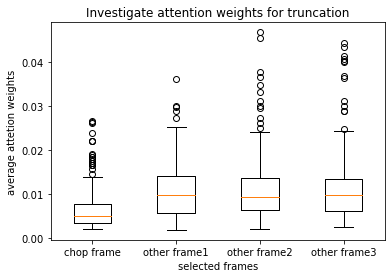

In [103]:
plt.boxplot(np.array(chop_res))
plt.xticks([1, 2, 3, 4], ["chop frame", "other frame1", "other frame2", "other frame3"])
plt.title("Investigate attention weights for truncation")
plt.xlabel("selected frames")
plt.ylabel("average attetion weights")
plt.show()

In [99]:
pad_res = []
for file in files_to_pad:
    with open("/dataNVME/neil/ASVspoof2019LAFeatures/train/"+file+"LFCC.pkl", 'rb') as feature_handle:
        sample1 = pickle.load(feature_handle)
        sample1 = torch.from_numpy(sample1).float().cuda()
        pad_res.append(draw_attention(sample1))

Original num of frames: 345
Padding
Original num of frames: 439
Padding
Original num of frames: 289
Padding
Original num of frames: 281
Padding
Original num of frames: 353
Padding
Original num of frames: 225
Padding
Original num of frames: 212
Padding
Original num of frames: 200
Padding
Original num of frames: 379
Padding
Original num of frames: 324
Padding
Original num of frames: 336
Padding
Original num of frames: 306
Padding
Original num of frames: 247
Padding
Original num of frames: 306
Padding
Original num of frames: 281
Padding
Original num of frames: 303
Padding
Original num of frames: 319
Padding
Original num of frames: 366
Padding
Original num of frames: 229
Padding
Original num of frames: 289
Padding
Original num of frames: 272
Padding
Original num of frames: 315
Padding
Original num of frames: 456
Padding
Original num of frames: 281
Padding
Original num of frames: 382
Padding
Original num of frames: 405
Padding
Original num of frames: 422
Padding
Original num of frames: 259


Original num of frames: 182
Padding
Original num of frames: 251
Padding
Original num of frames: 234
Padding
Original num of frames: 490
Padding
Original num of frames: 353
Padding
Original num of frames: 426
Padding
Original num of frames: 298
Padding
Original num of frames: 276
Padding
Original num of frames: 319
Padding
Original num of frames: 341
Padding
Original num of frames: 255
Padding
Original num of frames: 375
Padding
Original num of frames: 447
Padding
Original num of frames: 388
Padding
Original num of frames: 383
Padding
Original num of frames: 379
Padding
Original num of frames: 323
Padding
Original num of frames: 302
Padding
Original num of frames: 349
Padding
Original num of frames: 405
Padding
Original num of frames: 340
Padding
Original num of frames: 280
Padding
Original num of frames: 340
Padding
Original num of frames: 430
Padding
Original num of frames: 242
Padding
Original num of frames: 293
Padding
Original num of frames: 302
Padding
Original num of frames: 442


Original num of frames: 383
Padding
Original num of frames: 353
Padding
Original num of frames: 520
Padding
Original num of frames: 336
Padding
Original num of frames: 387
Padding
Original num of frames: 310
Padding
Original num of frames: 422
Padding
Original num of frames: 341
Padding
Original num of frames: 285
Padding
Original num of frames: 396
Padding
Original num of frames: 430
Padding
Original num of frames: 302
Padding
Original num of frames: 362
Padding
Original num of frames: 298
Padding
Original num of frames: 362
Padding
Original num of frames: 290
Padding
Original num of frames: 319
Padding
Original num of frames: 174
Padding
Original num of frames: 405
Padding
Original num of frames: 354
Padding
Original num of frames: 336
Padding
Original num of frames: 328
Padding
Original num of frames: 358
Padding
Original num of frames: 520
Padding
Original num of frames: 520
Padding
Original num of frames: 345
Padding
Original num of frames: 515
Padding
Original num of frames: 315


Original num of frames: 328
Padding
Original num of frames: 357
Padding
Original num of frames: 345
Padding
Original num of frames: 379
Padding
Original num of frames: 421
Padding
Original num of frames: 434
Padding
Original num of frames: 310
Padding
Original num of frames: 306
Padding
Original num of frames: 379
Padding
Original num of frames: 515
Padding
Original num of frames: 345
Padding
Original num of frames: 276
Padding
Original num of frames: 251
Padding
Original num of frames: 315
Padding
Original num of frames: 507
Padding
Original num of frames: 413
Padding
Original num of frames: 302
Padding
Original num of frames: 230
Padding
Original num of frames: 353
Padding
Original num of frames: 332
Padding
Original num of frames: 268
Padding
Original num of frames: 267
Padding
Original num of frames: 349
Padding
Original num of frames: 289
Padding
Original num of frames: 302
Padding
Original num of frames: 260
Padding
Original num of frames: 371
Padding
Original num of frames: 285


Original num of frames: 221
Padding
Original num of frames: 328
Padding
Original num of frames: 264
Padding
Original num of frames: 238
Padding
Original num of frames: 221
Padding
Original num of frames: 242
Padding
Original num of frames: 242
Padding
Original num of frames: 250
Padding
Original num of frames: 251
Padding
Original num of frames: 251
Padding
Original num of frames: 238
Padding
Original num of frames: 285
Padding
Original num of frames: 217
Padding
Original num of frames: 289
Padding
Original num of frames: 324
Padding
Original num of frames: 264
Padding
Original num of frames: 195
Padding
Original num of frames: 256
Padding
Original num of frames: 230
Padding
Original num of frames: 349
Padding
Original num of frames: 225
Padding
Original num of frames: 221
Padding
Original num of frames: 280
Padding
Original num of frames: 285
Padding
Original num of frames: 383
Padding
Original num of frames: 242
Padding
Original num of frames: 268
Padding
Original num of frames: 331


Original num of frames: 221
Padding
Original num of frames: 400
Padding
Original num of frames: 277
Padding
Original num of frames: 494
Padding
Original num of frames: 294
Padding
Original num of frames: 337
Padding
Original num of frames: 281
Padding
Original num of frames: 430
Padding
Original num of frames: 383
Padding
Original num of frames: 221
Padding
Original num of frames: 507
Padding
Original num of frames: 396
Padding
Original num of frames: 217
Padding
Original num of frames: 400
Padding
Original num of frames: 276
Padding
Original num of frames: 276
Padding
Original num of frames: 426
Padding
Original num of frames: 358
Padding
Original num of frames: 370
Padding
Original num of frames: 362
Padding
Original num of frames: 456
Padding
Original num of frames: 302
Padding
Original num of frames: 264
Padding
Original num of frames: 460
Padding
Original num of frames: 345
Padding
Original num of frames: 289
Padding
Original num of frames: 302
Padding
Original num of frames: 268


... (89 outputs left out)

Padding
Original num of frames: 280
Padding
Original num of frames: 238
Padding
Original num of frames: 323
Padding
Original num of frames: 327
Padding
Original num of frames: 289
Padding
Original num of frames: 267
Padding
Original num of frames: 421
Padding
Original num of frames: 293
Padding
Original num of frames: 310
Padding
Original num of frames: 314
Padding
Original num of frames: 174
Padding
Original num of frames: 276
Padding
Original num of frames: 306
Padding
Original num of frames: 284
Padding
Original num of frames: 374
Padding
Original num of frames: 203
Padding
Original num of frames: 421
Padding
Original num of frames: 276
Padding
Original num of frames: 280
Padding
Original num of frames: 297
Padding
Original num of frames: 259
Padding
Original num of frames: 284
Padding
Original num of frames: 259
Padding
Original num of frames: 344
Padding
Original num of frames: 216
Padding
Original num of frames: 211
Padding
Original num of frames: 281
Padding
Original num of fram

Original num of frames: 421
Padding
Original num of frames: 609
Padding
Original num of frames: 233
Padding
Original num of frames: 319
Padding
Original num of frames: 289
Padding
Original num of frames: 272
Padding
Original num of frames: 370
Padding
Original num of frames: 302
Padding
Original num of frames: 417
Padding
Original num of frames: 362
Padding
Original num of frames: 228
Padding
Original num of frames: 255
Padding
Original num of frames: 306
Padding
Original num of frames: 255
Padding
Original num of frames: 348
Padding
Original num of frames: 225
Padding
Original num of frames: 255
Padding
Original num of frames: 221
Padding
Original num of frames: 255
Padding
Original num of frames: 267
Padding
Original num of frames: 246
Padding
Original num of frames: 374
Padding
Original num of frames: 268
Padding
Original num of frames: 327
Padding
Original num of frames: 434
Padding
Original num of frames: 332
Padding
Original num of frames: 293
Padding
Original num of frames: 366


Original num of frames: 332
Padding
Original num of frames: 259
Padding
Original num of frames: 327
Padding
Original num of frames: 268
Padding
Original num of frames: 310
Padding
Original num of frames: 328
Padding
Original num of frames: 609
Padding
Original num of frames: 174
Padding
Original num of frames: 258
Padding
Original num of frames: 344
Padding
Original num of frames: 225
Padding
Original num of frames: 349
Padding
Original num of frames: 344
Padding
Original num of frames: 383
Padding
Original num of frames: 369
Padding
Original num of frames: 340
Padding
Original num of frames: 234
Padding
Original num of frames: 238
Padding
Original num of frames: 349
Padding
Original num of frames: 336
Padding
Original num of frames: 195
Padding
Original num of frames: 379
Padding
Original num of frames: 289
Padding
Original num of frames: 332
Padding
Original num of frames: 357
Padding
Original num of frames: 379
Padding
Original num of frames: 233
Padding
Original num of frames: 246


Original num of frames: 233
Padding
Original num of frames: 434
Padding
Original num of frames: 408
Padding
Original num of frames: 232
Padding
Original num of frames: 455
Padding
Original num of frames: 357
Padding
Original num of frames: 460
Padding
Original num of frames: 553
Padding
Original num of frames: 460
Padding
Original num of frames: 579
Padding
Original num of frames: 417
Padding
Original num of frames: 357
Padding
Original num of frames: 221
Padding
Original num of frames: 579
Padding
Original num of frames: 157
Padding
Original num of frames: 485
Padding
Original num of frames: 348
Padding
Original num of frames: 511
Padding
Original num of frames: 344
Padding
Original num of frames: 297
Padding
Original num of frames: 468
Padding
Original num of frames: 438
Padding
Original num of frames: 366
Padding
Original num of frames: 511
Padding
Original num of frames: 263
Padding
Original num of frames: 392
Padding
Original num of frames: 506
Padding
Original num of frames: 390


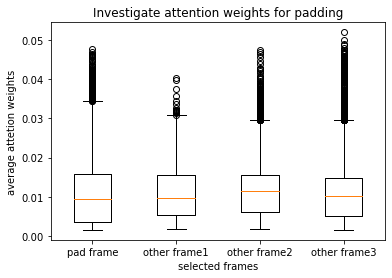

In [102]:
plt.boxplot(np.array(pad_res))
plt.xticks([1, 2, 3, 4], ["pad frame", "other frame1", "other frame2", "other frame3"])
plt.title("Investigate attention weights for padding")
plt.xlabel("selected frames")
plt.ylabel("average attetion weights")
plt.show()